In [7]:
# State
from typing import TypedDict
class AgentState(TypedDict):
    task: str
    status: str
    response: str


In [8]:
# Agent Node
def execute_task(state: AgentState):
    return {
        "response": f"Task accepted and executed: {state['task']}"
    }

# Guardrail Node
def guardrail(state: AgentState):
    task = state["task"].lower()

    blocked_keywords = [
        "delete",
        "remove",
        "destroy",
        "drop",
        "update",
        "modify",
        "edit",
        "change",
        "alter"
    ]

    if any(keyword in task for keyword in blocked_keywords):
        return {
            "status": "blocked",
            "response": (
                "Request denied. "
                "Delete and Update operations are not allowed."
            )
        }

    return {
        "status": "approved"
    }

In [9]:
# Routing Logic
def router(state: AgentState):
    if state["status"] == "blocked":
        return END
    return "execute_task"


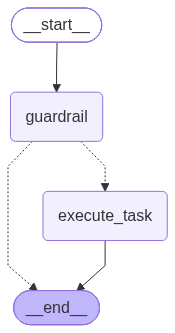

In [11]:
# Graph
from langgraph.graph import StateGraph, END
builder = StateGraph(AgentState)

builder.add_node("guardrail", guardrail)
builder.add_node("execute_task", execute_task)

builder.set_entry_point("guardrail")

builder.add_conditional_edges(
    "guardrail",
    router,
    {
        "execute_task": "execute_task",
        END: END
    }
)

builder.add_edge("execute_task", END)

graph = builder.compile()
graph

In [12]:
result = graph.invoke({
    "task": "create a new VM"
})

print(result)

{'task': 'create a new VM', 'status': 'approved', 'response': 'Task accepted and executed: create a new VM'}


In [14]:
result = graph.invoke({
    "task": "delete resource group rg-prod"
})

print(result)

{'task': 'delete resource group rg-prod', 'status': 'blocked', 'response': 'Request denied. Delete and Update operations are not allowed.'}
